In [6]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "data.py").exists():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT))

from data import load

df = load("listings")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (150000, 22)


,ml_num,sold_price,list_price,date_listed,date_sold,days_on_market,house_type_name,house_style,bedrooms,washrooms,...,house_area,lot_front,lot_depth,municipality,community,latitude,longitude,external_avm_estimate,external_avm_estimate_date,remarks
0,SYN-0023247,364100.0,371200.0,2020-12-29,2021-01-01,3,Condo Apt,Apartment,1,1,...,622,NaN,NaN,Toronto,Sumacpark,43.602039,-79.261184,366200.0,2021-02-14,Looking For More Space In A Turnkey Condo? Thi...
1,SYN-0156988,599000.0,595800.0,2020-12-26,2021-01-01,6,Condo Apt,Apartment,2,1,...,649,NaN,NaN,Toronto,Hickorymills,43.695388,-79.510865,622800.0,2021-12-26,"Imagine a quiet evening on Sequoia Trail, wher..."
2,SYN-0087706,492900.0,462200.0,2020-12-22,2021-01-01,10,Condo Apt,Apartment,2,1,...,900-1099,NaN,NaN,North York,Hazelmills,43.740512,-79.386216,NaN,2020-12-03,"Discover this inviting 2-bedroom, 1-bath condo..."
3,SYN-0128154,532300.0,524900.0,2020-12-19,2021-01-01,13,Condo Apt,Apartment,1,1,...,876,NaN,NaN,Scarborough,Sumacbank,43.643774,-79.470180,573600.0,2021-02-22,Sumacbank presents this 1-bedroom condo on Mag...
4,SYN-0118596,564100.0,558300.0,2020-12-05,2021-01-01,27,Condo Apt,Apartment,1,1,...,514,NaN,NaN,Toronto,Ashworth,43.696172,-79.274137,513000.0,2021-02-05,"Morning coffee at the kitchen island, then a s..."


In [7]:
print("Number of rows:", len(df))
print("Number of columns:", len(df.columns))

df.info()

display(df.describe(include="all").T)

Number of rows: 150000
Number of columns: 22
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 22 columns):
 #   Column                      Non-Null Count   Dtype         
---  ------                      --------------   -----         
 0   ml_num                      150000 non-null  object        
 1   sold_price                  150000 non-null  float64       
 2   list_price                  150000 non-null  float64       
 3   date_listed                 150000 non-null  datetime64[us]
 4   date_sold                   150000 non-null  datetime64[us]
 5   days_on_market              150000 non-null  int64         
 6   house_type_name             150000 non-null  object        
 7   house_style                 150000 non-null  object        
 8   bedrooms                    150000 non-null  int64         
 9   washrooms                   150000 non-null  int64         
 10  parking_total               150000 non-null  int64         

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
ml_num,150000,150000,SYN-0023247,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sold_price,150000.0,NaN,NaN,NaN,1073917.036,172600.0,623700.0,856650.0,1239800.0,30000000.0,812529.953536
list_price,150000.0,NaN,NaN,NaN,1074504.908667,161800.0,631700.0,859700.0,1233900.0,28078000.0,810471.62734
date_listed,150000,NaN,NaN,NaN,2023-04-16 14:02:04.992000,2020-02-19 00:00:00,2021-10-25 00:00:00,2023-03-11 00:00:00,2024-08-24 00:00:00,2026-05-29 00:00:00,NaN
date_sold,150000,NaN,NaN,NaN,2023-05-08 20:15:59.040000,2021-01-01 00:00:00,2021-11-08 00:00:00,2023-03-30 00:00:00,2024-09-28 00:00:00,2026-05-31 00:00:00,NaN
days_on_market,150000.0,NaN,NaN,NaN,22.259653,0.0,6.0,12.0,26.0,320.0,31.628163
house_type_name,150000,6,Condo Apt,76374,NaN,NaN,NaN,NaN,NaN,NaN,NaN
house_style,150000,16,Apartment,72455,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bedrooms,150000.0,NaN,NaN,NaN,2.341673,0.0,1.0,2.0,3.0,6.0,1.106252
washrooms,150000.0,NaN,NaN,NaN,2.158313,1.0,1.0,2.0,3.0,6.0,1.109122


In [8]:
missing = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": df.isna().mean() * 100
})

missing = missing.sort_values(
    "Missing Percentage",
    ascending=False
)

display(missing)

,Missing Count,Missing Percentage
lot_depth,87263,58.175333
lot_front,87263,58.175333
external_avm_estimate,1306,0.870667
ml_num,0,0.000000
sold_price,0,0.000000
external_avm_estimate_date,0,0.000000
longitude,0,0.000000
latitude,0,0.000000
community,0,0.000000
municipality,0,0.000000


In [9]:
# Are missing lot dimensions associated with property type?
lot_missing_by_type = (
    df.groupby("house_type_name")
    .agg(
        total_homes=("ml_num", "size"),
        lot_front_missing=(
            "lot_front",
            lambda x: x.isna().mean() * 100
        ),
        lot_depth_missing=(
            "lot_depth",
            lambda x: x.isna().mean() * 100
        )
    )
    .round(2)
)

display(lot_missing_by_type)

,total_homes,lot_front_missing,lot_depth_missing
house_type_name,,,
Co-Op Apt,729,100.0,100.0
Condo Apt,76374,100.0,100.0
Condo Townhouse,10160,100.0,100.0
Detached,43202,0.0,0.0
Freehold Townhouse,5138,0.0,0.0
Semi-Detached,14397,0.0,0.0


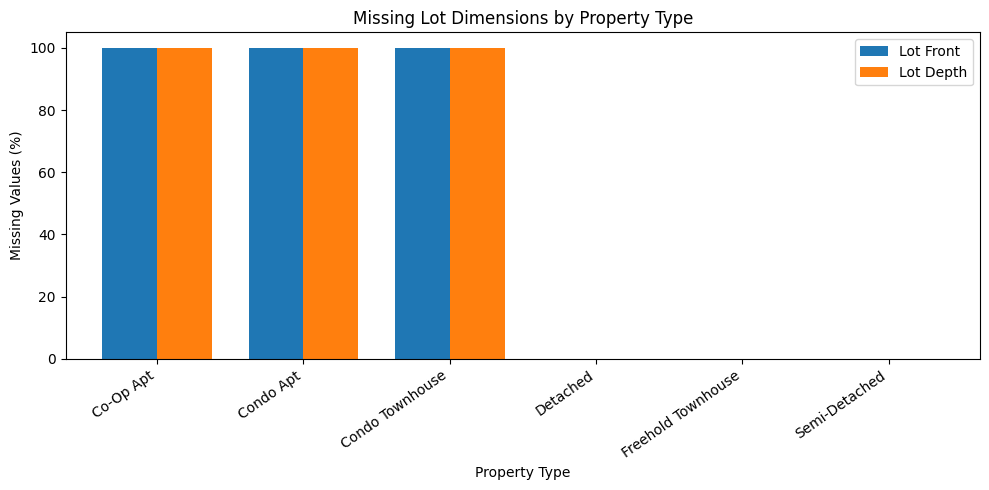

In [10]:
ax = lot_missing_by_type[
    ["lot_front_missing", "lot_depth_missing"]
].plot(
    kind="bar",
    figsize=(10, 5),
    width=0.75
)

plt.title("Missing Lot Dimensions by Property Type")
plt.xlabel("Property Type")
plt.ylabel("Missing Values (%)")
plt.xticks(rotation=35, ha="right")
plt.ylim(0, 105)
plt.legend(["Lot Front", "Lot Depth"])
plt.tight_layout()


plt.show()

In [11]:
# How does the median sold price vary across different property types?
price_by_type = (
    df.groupby("house_type_name")["sold_price"]
    .agg(["count", "mean", "median", "std"])
    .sort_values("median", ascending=False)
)

display(price_by_type.round(2))

,count,mean,median,std
house_type_name,,,,
Detached,43202,1688777.61,1367850.0,1153124.38
Semi-Detached,14397,1322291.15,1179100.0,565621.88
Freehold Townhouse,5138,1283139.04,1146600.0,506767.35
Condo Townhouse,10160,842632.68,786200.0,273856.26
Co-Op Apt,729,755315.64,646600.0,556019.33
Condo Apt,76374,699026.08,644300.0,277399.40


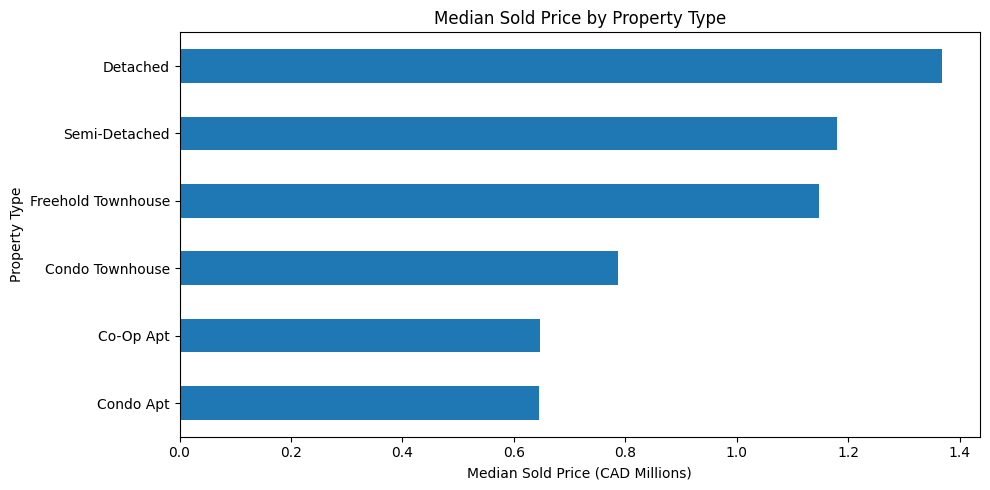

In [12]:
price_millions = (
        df.groupby("house_type_name")["sold_price"]
        .median()
        .sort_values()
        / 1_000_000
)

plt.figure(figsize=(10, 5))

price_millions.plot(kind="barh")

plt.title("Median Sold Price by Property Type")
plt.xlabel("Median Sold Price (CAD Millions)")
plt.ylabel("Property Type")
plt.tight_layout()

plt.show()

In [13]:
print("House Area Data Type:")
print(df["house_area"].dtype)

print("\nMost Common House Area Values:")
display(df["house_area"].value_counts().head(20))

print("\nSample Values:")
print(df["house_area"].sample(20, random_state=42).tolist())

House Area Data Type:
object

Most Common House Area Values:


house_area
700-899      6282
600-799      6101
800-999      4298
900-1099     3934
1000-1199    3714
1100-1299    3648
1200-1399    3426
500-699      3422
1300-1499    3250
1400-1599    2815
1500-1699    2472
1600-1799    2121
1700-1899    1832
1800-1999    1335
1900-2099    1192
2000-2199    1053
400-599       909
2100-2299     885
2200-2399     858
2300-2499     691
Name: count, dtype: int64


Sample Values:
['600-799', '3145', '1500-1699', '1191', '700-899', '611', '963', '1768', '940', '900-1099', '768', '600-799', '532', '600-799', '1500-1699', '733', '2112', '1765', '1300-1499', '638']


In [14]:
area_by_type = (
    df.groupby("house_type_name")["house_area"]
    .agg(["count", "nunique"])
)

display(area_by_type)

,count,nunique
house_type_name,,
Co-Op Apt,729,345
Condo Apt,76374,1992
Condo Townhouse,10160,1613
Detached,43202,4576
Freehold Townhouse,5138,1516
Semi-Detached,14397,2146


In [15]:
from data import load
from features import square_feet

# Reload the dataset in the current kernel
df = load("listings")

# Convert house area to numeric values
df["house_area_numeric"] = square_feet(df["house_area"])

# Display the original and converted values
display(df[["house_area", "house_area_numeric"]].head(20))

,house_area,house_area_numeric
0,622,622.0
1,649,649.0
2,900-1099,999.5
3,876,876.0
4,514,514.0
5,1500-1699,1599.5
6,562,562.0
7,1000-1199,1099.5
8,723,723.0
9,1000-1199,1099.5


In [16]:
print("Original missing values:")
print(df["house_area"].isna().sum())

print("\nConverted missing values:")
print(df["house_area_numeric"].isna().sum())

print("\nSummary statistics:")
display(df["house_area_numeric"].describe())

print("\nUnconverted non-missing values:")
failed = df.loc[
    df["house_area"].notna()
    & df["house_area_numeric"].isna(),
    "house_area"
]

display(failed.value_counts().head(20))

Original missing values:
0

Converted missing values:
0

Summary statistics:


count    150000.000000
mean       1380.156917
std         898.541589
min         300.000000
25%         799.500000
50%        1142.000000
75%        1644.000000
max        9099.500000
Name: house_area_numeric, dtype: float64


Unconverted non-missing values:


Series([], Name: count, dtype: int64)

In [17]:
print("House Area Summary Statistics:")
print(
    df["house_area_numeric"].describe(
        percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
    )
)

print("\nSmallest 10 Values:")
print(df["house_area_numeric"].nsmallest(10).tolist())

print("\nLargest 10 Values:")
print(df["house_area_numeric"].nlargest(10).tolist())

House Area Summary Statistics:
count    150000.000000
mean       1380.156917
std         898.541589
min         300.000000
1%          492.000000
5%          596.000000
25%         799.500000
50%        1142.000000
75%        1644.000000
95%        2999.500000
99%        4899.500000
max        9099.500000
Name: house_area_numeric, dtype: float64

Smallest 10 Values:
[300.0, 300.0, 300.0, 300.0, 300.0, 300.0, 300.0, 300.0, 300.0, 311.0]

Largest 10 Values:
[9099.5, 9099.5, 9099.5, 9099.5, 9099.5, 9099.5, 9099.5, 9099.5, 9099.5, 9099.5]


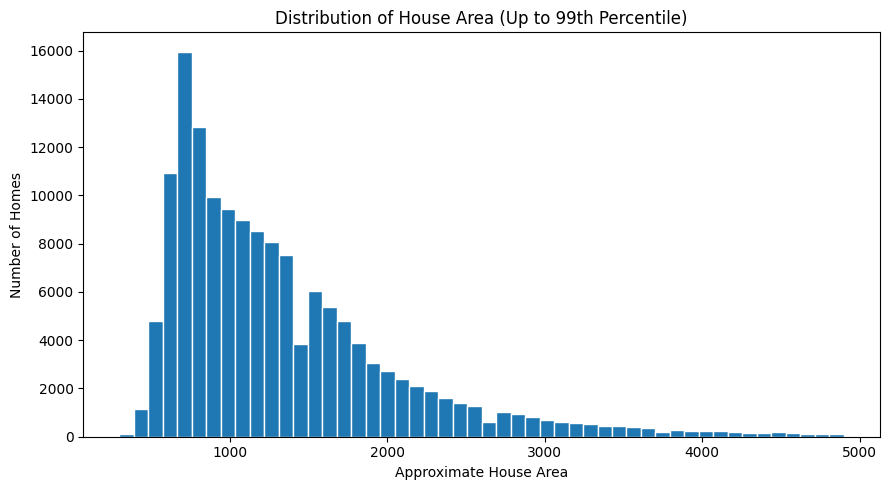

In [18]:
import matplotlib.pyplot as plt
from pathlib import Path

Path("figures").mkdir(exist_ok=True)

upper_limit = df["house_area_numeric"].quantile(0.99)

plt.figure(figsize=(9, 5))

plt.hist(
    df.loc[
        df["house_area_numeric"].between(0, upper_limit),
        "house_area_numeric"
    ],
    bins=50,
    edgecolor="white"
)

plt.title("Distribution of House Area (Up to 99th Percentile)")
plt.xlabel("Approximate House Area")
plt.ylabel("Number of Homes")

plt.tight_layout()
plt.show()

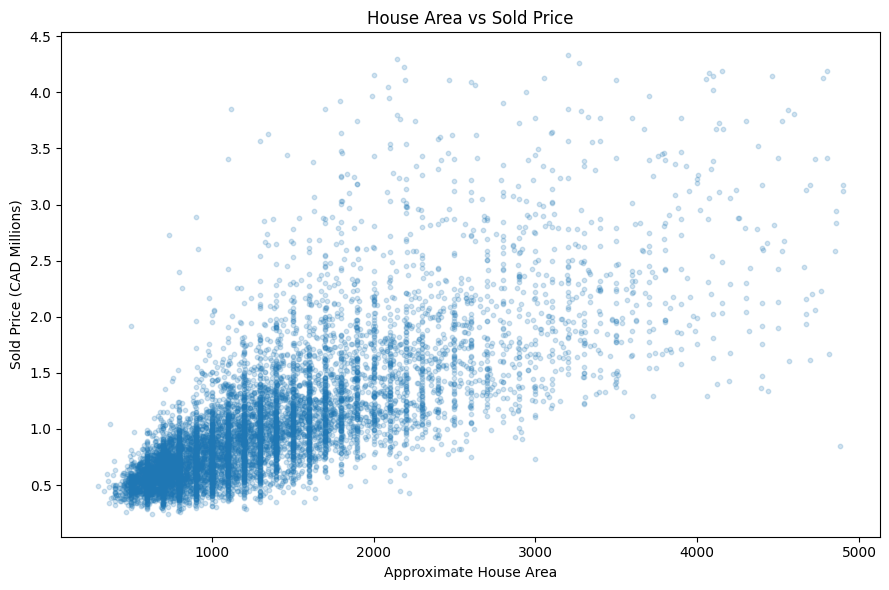

In [19]:
# How is house area associated with sold price, and are there any nonlinear patterns or extreme observations?
plot_df = df[
    (df["house_area_numeric"] > 0)
    & (df["sold_price"] > 0)
    ].copy()

area_limit = plot_df["house_area_numeric"].quantile(0.99)
price_limit = plot_df["sold_price"].quantile(0.99)

plot_df = plot_df[
    (plot_df["house_area_numeric"] <= area_limit)
    & (plot_df["sold_price"] <= price_limit)
    ]

plot_df = plot_df.sample(
    n=min(10000, len(plot_df)),
    random_state=42
)

plt.figure(figsize=(9, 6))

plt.scatter(
    plot_df["house_area_numeric"],
    plot_df["sold_price"] / 1_000_000,
    alpha=0.2,
    s=10
)

plt.xlabel("Approximate House Area")
plt.ylabel("Sold Price (CAD Millions)")
plt.title("House Area vs Sold Price")

plt.tight_layout()
plt.show()

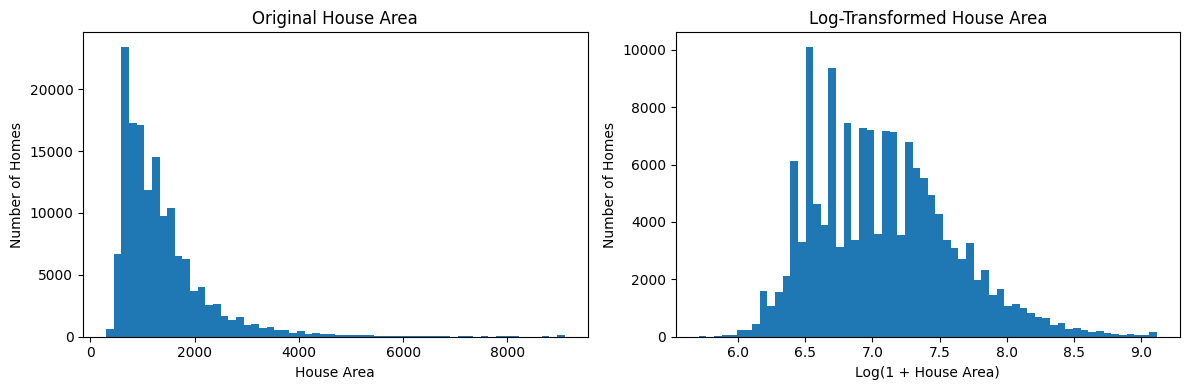

Original Skewness: 2.9004712672592583
Log Skewness: 0.6040638792324698


In [20]:
import numpy as np
import matplotlib.pyplot as plt

df["log_house_area"] = np.log1p(
    df["house_area_numeric"]
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(
    df["house_area_numeric"],
    bins=60
)
axes[0].set_title("Original House Area")
axes[0].set_xlabel("House Area")
axes[0].set_ylabel("Number of Homes")

axes[1].hist(
    df["log_house_area"],
    bins=60
)
axes[1].set_title("Log-Transformed House Area")
axes[1].set_xlabel("Log(1 + House Area)")
axes[1].set_ylabel("Number of Homes")

plt.tight_layout()
plt.show()

print("Original Skewness:",
      df["house_area_numeric"].skew())

print("Log Skewness:",
      df["log_house_area"].skew())

,count,mean,median,std
municipality,,,,
Toronto,85323,1124122.95,894600.0,860821.73
North York,27555,1038978.84,835800.0,782344.91
Scarborough,21078,1028169.12,814100.0,790277.90
York,1729,886261.42,786200.0,363870.70
Etobicoke,14315,931949.44,742600.0,585444.51


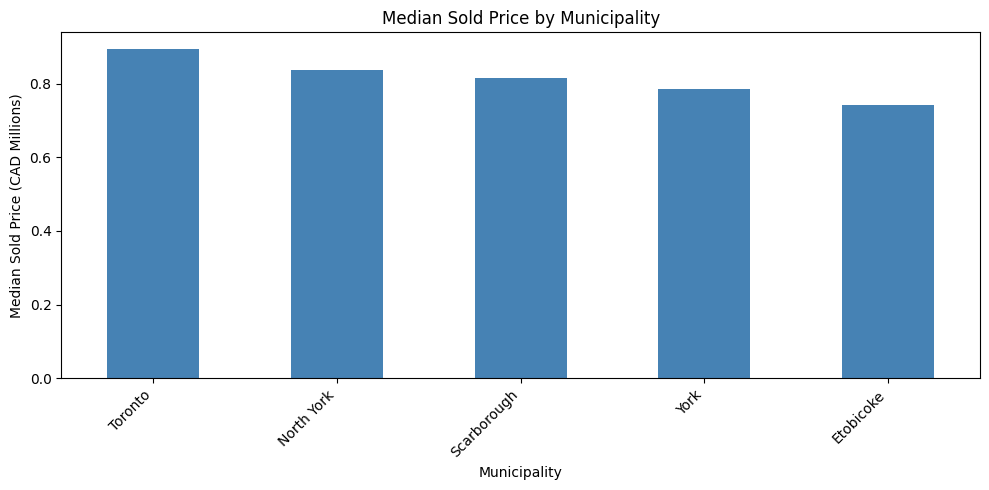

In [21]:
# Municipality Distribution and Sold Prices

municipality_summary = (
    df.groupby("municipality")["sold_price"]
    .agg(["count", "mean", "median", "std"])
    .sort_values("median", ascending=False)
)

display(municipality_summary.round(2))

# Plot median sold price by municipality
median_prices = (
        municipality_summary["median"] / 1_000_000
)

plt.figure(figsize=(10, 5))

median_prices.plot(
    kind="bar",
    color="steelblue"
)

plt.title("Median Sold Price by Municipality")
plt.xlabel("Municipality")
plt.ylabel("Median Sold Price (CAD Millions)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()

plt.show()

In [22]:
# Community-Level Price Analysis

community_summary = (
    df.groupby("community")["sold_price"]
    .agg(["count", "mean", "median", "std"])
    .sort_values("count", ascending=False)
)

print("Number of communities:", len(community_summary))

print("\nTop 15 Communities by Number of Sales:")
display(community_summary.head(15).round(2))

print("\nCommunities with Fewer Than 30 Sales:")
small_communities = community_summary[
    community_summary["count"] < 30
    ]

display(small_communities)

print("Number of communities with fewer than 30 sales:",
      len(small_communities))

Number of communities: 145

Top 15 Communities by Number of Sales:


,count,mean,median,std
community,,,,
Hickoryhaven,3584,786941.16,716700.0,313069.67
Willowglen,3337,813520.95,767400.0,295130.83
Elmview,2917,1171441.65,1001700.0,675661.27
Cedarview,2871,583059.46,544800.0,196725.78
Beechbourne,2821,1031340.38,840800.0,576974.73
Hemlockvale,2774,1431804.40,1327550.0,585239.87
Junipergardens,2747,1380479.76,1190500.0,767468.15
Ashworth,2487,1076800.92,876100.0,686749.92
Hickorybourne,2442,709526.86,662450.0,237628.19



Communities with Fewer Than 30 Sales:


,count,mean,median,std
community,,,,


Number of communities with fewer than 30 sales: 0


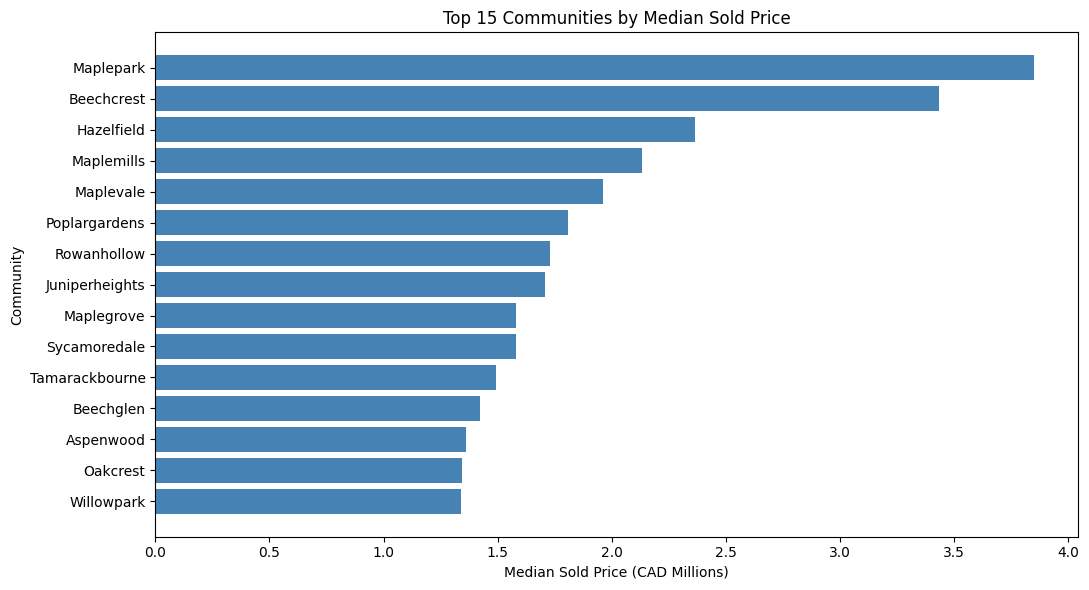

In [23]:
# Compare median sold prices across communities
# Restrict to communities with at least 100 sales

eligible_communities = community_summary[
    community_summary["count"] >= 100
    ]

top_communities = (
    eligible_communities
    .sort_values("median", ascending=False)
    .head(15)
)

plt.figure(figsize=(11, 6))

plt.barh(
    top_communities.index[::-1],
    top_communities["median"][::-1] / 1_000_000,
    color="steelblue"
)

plt.title("Top 15 Communities by Median Sold Price")
plt.xlabel("Median Sold Price (CAD Millions)")
plt.ylabel("Community")

plt.tight_layout()

plt.show()

In [24]:
# Latitude and Longitude Summary

location_summary = df[
    ["latitude", "longitude"]
].describe()

display(location_summary)

print("Missing latitude:",
      df["latitude"].isna().sum())

print("Missing longitude:",
      df["longitude"].isna().sum())

print("Latitude unique values:",
      df["latitude"].nunique())

print("Longitude unique values:",
      df["longitude"].nunique())

,latitude,longitude
count,150000.000000,150000.000000
mean,43.643452,-79.378654
std,0.054368,0.100594
min,43.490027,-79.597572
25%,43.600888,-79.445734
50%,43.642058,-79.391685
75%,43.679629,-79.313684
max,43.843841,-79.070793


Missing latitude: 0
Missing longitude: 0
Latitude unique values: 62844
Longitude unique values: 62844


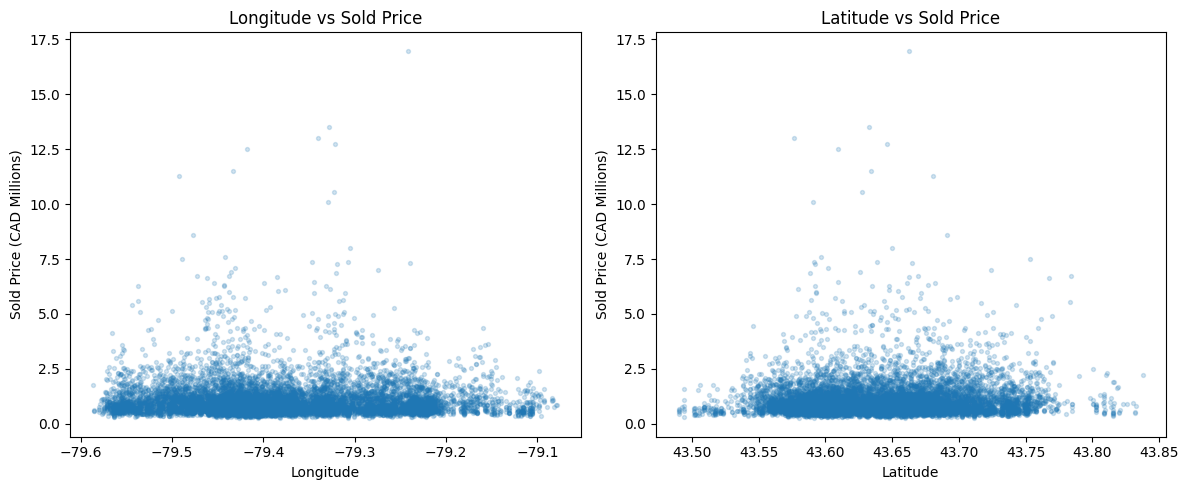

In [25]:
# Coordinate and Sold Price Relationship

import matplotlib.pyplot as plt

sample_df = df.sample(
    n=min(10000, len(df)),
    random_state=42
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(
    sample_df["longitude"],
    sample_df["sold_price"] / 1_000_000,
    alpha=0.2,
    s=8
)

axes[0].set_title("Longitude vs Sold Price")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Sold Price (CAD Millions)")

axes[1].scatter(
    sample_df["latitude"],
    sample_df["sold_price"] / 1_000_000,
    alpha=0.2,
    s=8
)

axes[1].set_title("Latitude vs Sold Price")
axes[1].set_xlabel("Latitude")
axes[1].set_ylabel("Sold Price (CAD Millions)")

plt.tight_layout()

plt.show()

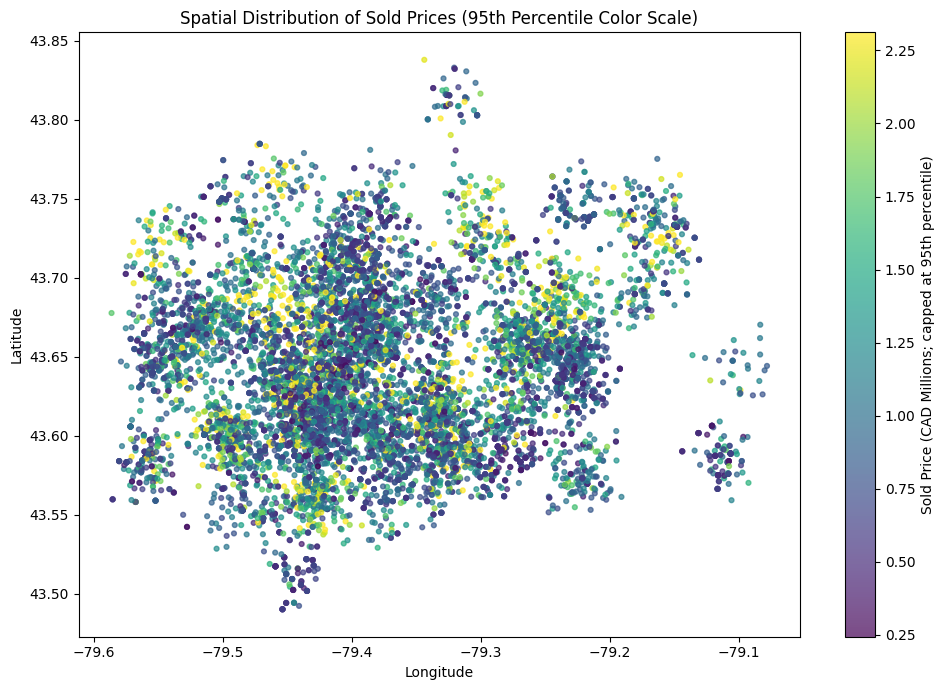

In [26]:
# Spatial Price Distribution
# Spatial Price Distribution
import matplotlib.colors as colors

price_millions = sample_df["sold_price"] / 1_000_000

price_95 = price_millions.quantile(0.95)

plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    sample_df["longitude"],
    sample_df["latitude"],
    c=price_millions,
    cmap="viridis",
    norm=colors.Normalize(
        vmin=price_millions.min(),
        vmax=price_95,
        clip=True
    ),
    alpha=0.7,
    s=12
)

plt.colorbar(
    scatter,
    label="Sold Price (CAD Millions; capped at 95th percentile)"
)

plt.title("Spatial Distribution of Sold Prices (95th Percentile Color Scale)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.tight_layout()

plt.show()

In [27]:
# 1. Data Audit and Analysis Sample
# Preserve the original df. Exclude missing, nonpositive and nonfinite sale prices only from the price-analysis copy. Do not remove records because of high prices. Report date-parsing failures separately.

for col in ['date_listed', 'date_sold', 'external_avm_estimate_date']:
    original = df[col].copy()
    df[col] = pd.to_datetime(original, errors='coerce')
    print(col, 'parse failures:', (original.notna() & df[col].isna()).sum())
for col in ['sold_price', 'list_price']:
    df[col] = pd.to_numeric(df[col], errors='coerce')
audit = pd.Series({
    'Rows': len(df), 'Duplicate ml_num': df['ml_num'].duplicated().sum(),
    'Missing sold date': df['date_sold'].isna().sum(),
    'Missing listed date': df['date_listed'].isna().sum(),
    'Invalid sold price': (~(np.isfinite(df['sold_price']) & df['sold_price'].gt(0))).sum(),
    'Invalid list price': (~(np.isfinite(df['list_price']) & df['list_price'].gt(0))).sum(),
    'Sold before listed': (df['date_sold'] < df['date_listed']).sum()
}, name='Count')
display(audit.to_frame())
eda = df.loc[np.isfinite(df['sold_price']) & df['sold_price'].gt(0)].copy()
eda['sale_month'] = eda['date_sold'].dt.to_period('M')
print('Sale date range:', df['date_sold'].min(), 'to', df['date_sold'].max())
print('Listing date range:', df['date_listed'].min(), 'to', df['date_listed'].max())

date_listed parse failures: 0
date_sold parse failures: 0
external_avm_estimate_date parse failures: 0


,Count
Rows,150000
Duplicate ml_num,0
Missing sold date,0
Missing listed date,0
Invalid sold price,0
Invalid list price,0
Sold before listed,0


Sale date range: 2021-01-01 00:00:00 to 2026-05-31 00:00:00
Listing date range: 2020-02-19 00:00:00 to 2026-05-29 00:00:00


,median_sold_price,transactions
2021-01,710800.0,2500
2021-02,788600.0,3573
2021-03,866400.0,5024
2021-04,888600.0,4377
2021-05,886000.0,4199
...,...,...
2026-01,744300.0,1058
2026-02,780100.0,1442
2026-03,804100.0,1816
2026-04,827550.0,2224


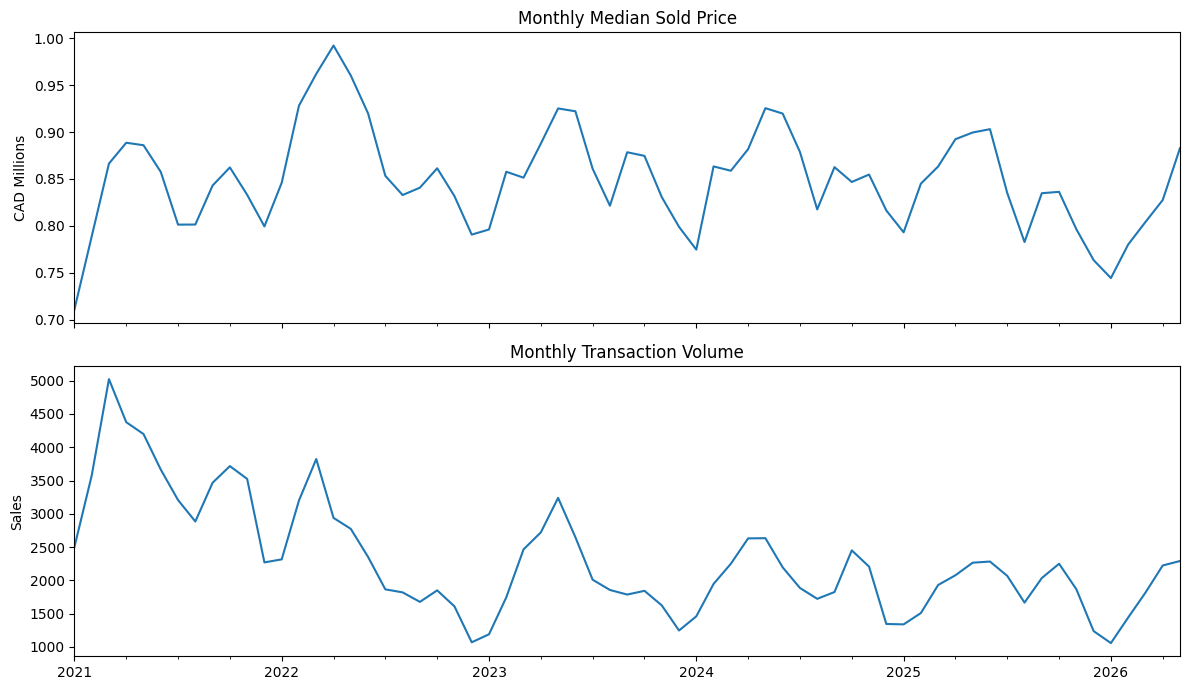

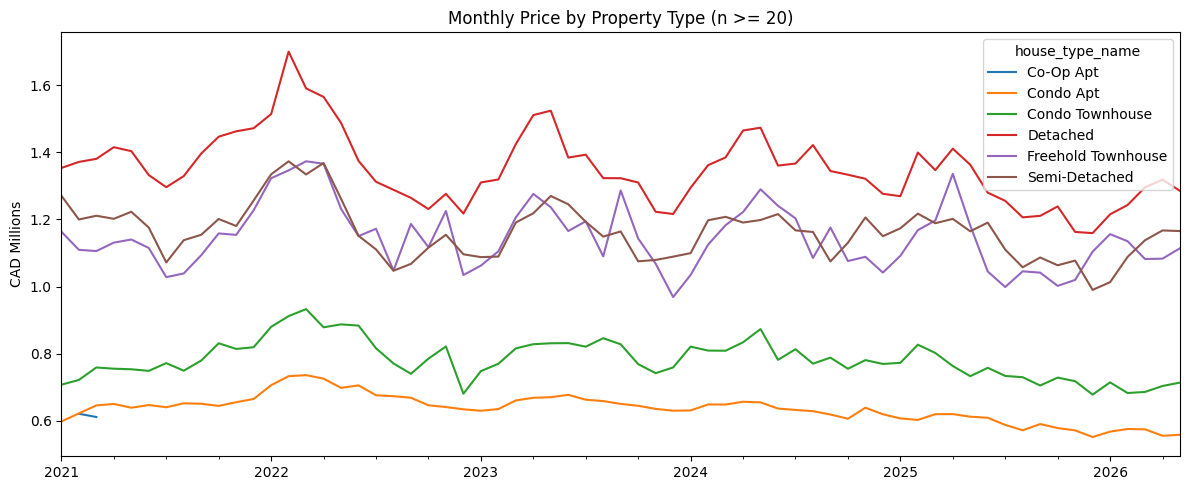

In [28]:
# 2. Temporal Analysis
# Examine monthly median sale prices, transaction volumes and trends by property type. Fill intervening months without sales with zero counts and missing prices. The first and last months may be incomplete. Overall medians depend on the mix of property types. Hide plotted prices for groups with fewer than 20 sales without removing their records.

dated = eda.dropna(subset=['sale_month'])
months = pd.period_range(dated['sale_month'].min(), dated['sale_month'].max(), freq='M')
monthly = dated.groupby('sale_month').agg(
    median_sold_price=('sold_price', 'median'), transactions=('sold_price', 'size')
).reindex(months)
monthly['transactions'] = monthly['transactions'].fillna(0).astype(int)
display(monthly)
plot = monthly.copy()
plot.index = plot.index.to_timestamp()
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
(plot['median_sold_price']/1e6).plot(ax=axes[0], title='Monthly Median Sold Price')
axes[0].set_ylabel('CAD Millions')
plot['transactions'].plot(ax=axes[1], title='Monthly Transaction Volume')
axes[1].set_ylabel('Sales')
plt.tight_layout(); plt.show()
by_type = dated.groupby(['sale_month', 'house_type_name']).agg(
    median_price=('sold_price', 'median'), n=('sold_price', 'size'))
trends = by_type['median_price'].where(by_type['n'] >= 20).unstack().reindex(months)
trends.index = trends.index.to_timestamp()
(trends/1e6).plot(figsize=(12, 5), title='Monthly Price by Property Type (n >= 20)')
plt.ylabel('CAD Millions'); plt.tight_layout(); plt.show()

,sold_price
count,1.500000e+05
mean,1.073917e+06
std,8.125300e+05
min,1.726000e+05
1%,3.567000e+05
5%,4.427000e+05
25%,6.237000e+05
50%,8.566500e+05
75%,1.239800e+06
95%,2.361410e+06


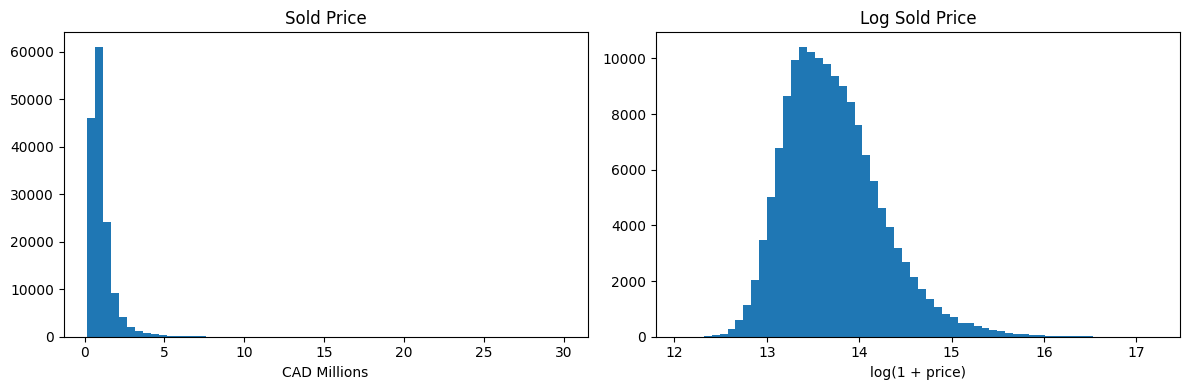

,ml_num,house_type_name,house_area,list_price,sold_price
58706,SYN-0003038,Detached,7085,28078000.0,30000000.0
50649,SYN-0074468,Detached,7900-8099,21276900.0,23145600.0
80964,SYN-0134687,Detached,5629,20037800.0,19842400.0
149910,SYN-0090330,Detached,9000,18203500.0,17035700.0
54452,SYN-0054091,Detached,9000,15372100.0,16984700.0
102492,SYN-0011021,Detached,9000-9199,16597200.0,16222800.0
101992,SYN-0119813,Detached,9000-9199,14778800.0,15939100.0
110250,SYN-0125484,Detached,8310,17683700.0,15238600.0
139726,SYN-0112147,Detached,7000-7199,12798900.0,15138300.0
32471,SYN-0028430,Detached,5786,14800100.0,14930500.0


,sale_to_list_ratio
count,150000.000000
mean,1.002296
std,0.107430
min,0.799868
1%,0.831470
5%,0.868491
50%,0.980265
95%,1.209709
99%,1.349167
max,1.700148


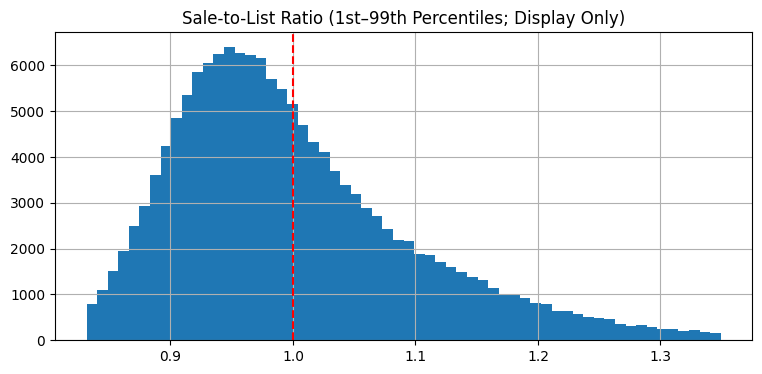

median_ratio     n
sale_month house_type_name                       
2021-01    Co-Op Apt               0.940160    13
           Condo Apt               0.964589  1594
           Condo Townhouse         1.034020   179
           Detached                1.023245   479
           Freehold Townhouse      1.063623    53
...                                     ...   ...
2026-05    Condo Apt               0.934171   962
           Condo Townhouse         0.972251   120
           Detached                0.962548   815
           Freehold Townhouse      0.962050    96
           Semi-Detached           1.005735   289

[390 rows x 2 columns]

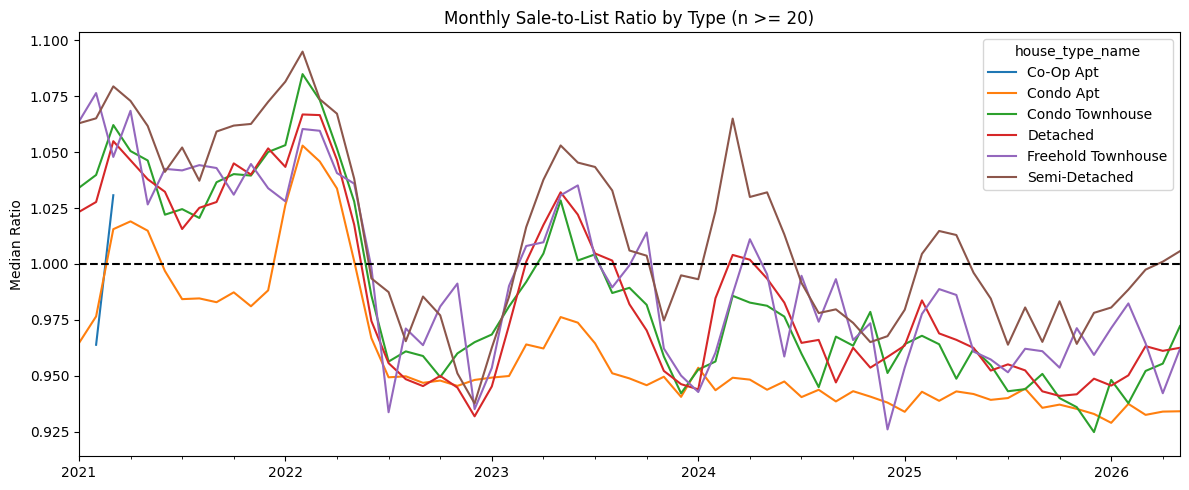

In [29]:
# 3. Sale Price Distribution and Sale-to-List Ratio
# Ratio = sold_price / list_price. It includes the target, so use it only for analysis or as a separately defined prediction target, never as an input for the current home. Plot trimming affects display only. Quantiles and summaries use the full valid sample.

display(eda['sold_price'].describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).to_frame())
fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes[0].hist(eda['sold_price']/1e6, bins=60)
axes[0].set(title='Sold Price', xlabel='CAD Millions')
axes[1].hist(np.log1p(eda['sold_price']), bins=60)
axes[1].set(title='Log Sold Price', xlabel='log(1 + price)')
plt.tight_layout(); plt.show()
display(eda.nlargest(10, 'sold_price')[['ml_num','house_type_name','house_area','list_price','sold_price']])
ratio_df = eda.loc[np.isfinite(eda['list_price']) & eda['list_price'].gt(0)].copy()
ratio_df['sale_to_list_ratio'] = ratio_df['sold_price']/ratio_df['list_price']
display(ratio_df['sale_to_list_ratio'].describe(percentiles=[.01,.05,.5,.95,.99]).to_frame())
lo, hi = ratio_df['sale_to_list_ratio'].quantile([.01,.99])
ratio_df.loc[ratio_df['sale_to_list_ratio'].between(lo,hi), 'sale_to_list_ratio'].hist(bins=60, figsize=(9,4))
plt.axvline(1,color='red',linestyle='--')
plt.title('Sale-to-List Ratio (1st–99th Percentiles; Display Only)'); plt.show()
ratio_summary = ratio_df.groupby(['sale_month','house_type_name']).agg(
    median_ratio=('sale_to_list_ratio','median'), n=('sale_to_list_ratio','size'))
display(ratio_summary)
rt = ratio_summary['median_ratio'].where(ratio_summary['n'] >= 20).unstack().reindex(months)
rt.index = rt.index.to_timestamp()
rt.plot(figsize=(12,5), title='Monthly Sale-to-List Ratio by Type (n >= 20)')
plt.axhline(1,color='black',linestyle='--'); plt.ylabel('Median Ratio'); plt.tight_layout(); plt.show()

In [30]:
# 4. Other Property Features
# Report overall summaries and comparisons within property types to reduce misleading effects from the property-type mix. Keep missing categories separate and interpret small samples cautiously. Association does not establish independent predictive value or causality.
tables = []
for col in ['bedrooms','washrooms','parking_total','garage','house_style']:
    overall = eda.groupby(col, dropna=False)['sold_price'].agg(n='size', median_price='median', mean_price='mean').reset_index().rename(columns={col:'value'})
    overall.insert(0, 'feature', col)
    tables.append(overall)
    print('Within property type:', col)
    display(eda.groupby(['house_type_name',col], dropna=False)['sold_price'].agg(n='size', median_price='median'))
feature_summary = pd.concat(tables, ignore_index=True)
display(feature_summary)

Within property type: bedrooms


n  median_price
house_type_name    bedrooms                     
Co-Op Apt          0            28      565800.0
                   1           270      605900.0
                   2           358      669150.0
                   3            72      785450.0
                   5             1     5780400.0
Condo Apt          0          2076      554300.0
                   1         35018      606600.0
                   2         34687      685200.0
                   3          4526      848300.0
                   4            67     1622800.0
Condo Townhouse    0            40      790400.0
                   1           655      754600.0
                   2          3404      754700.0
                   3          5201      789700.0
                   4           851      907400.0
                   5             9     1091100.0
Detached           0            76      823450.0
                   1           274      932450.0
                   2          4947     1034700.0
                   3         21893     1261700.0
                   4         12742     1621350.0
                   5          2533     2180900.0
                   6           737     3354900.0
Freehold Townhouse 0             2     1686100.0
                   1            51     1369800.0
                   2           649     1125500.0
                   3          3580     1134100.0
                   4           713     1173200.0
                   5           119     1369900.0
                   6            24     1559150.0
Semi-Detached      0            10     1292050.0
                   1            69     1158500.0
                   2          1340     1099600.0
                   3          9713     1151300.0
                   4          2673     1269900.0
                   5           423     1508600.0
                   6           169     2075900.0

Within property type: washrooms


n  median_price
house_type_name    washrooms                     
Co-Op Apt          1            560      608850.0
                   2            156      858050.0
                   3             10     1369500.0
                   5              3     5780400.0
Condo Apt          1          38144      572100.0
                   2          35620      739300.0
                   3           2361     1131400.0
                   4            176     1583300.0
                   5             73     2172300.0
Condo Townhouse    1           1210      641350.0
                   2           4592      736500.0
                   3           3805      871200.0
                   4            512     1131950.0
                   5             38     1491900.0
                   6              3     2337200.0
Detached           1           2058      876050.0
                   2          17711     1105600.0
                   3           9679     1391200.0
                   4           7768     1722150.0
                   5           3585     2190500.0
                   6           2401     3123600.0
Freehold Townhouse 1            266     1021150.0
                   2           1472     1045850.0
                   3           2256     1152100.0
                   4            972     1283900.0
                   5            152     1309500.0
                   6             20     2142750.0
Semi-Detached      1            858      985500.0
                   2           7651     1090100.0
                   3           3863     1260400.0
                   4           1504     1542700.0
                   5            328     2233100.0
                   6            193     2694400.0

Within property type: parking_total


n  median_price
house_type_name    parking_total                     
Co-Op Apt          0                140      704050.0
                   1                575      629500.0
                   2                 13      636300.0
                   6                  1     3310000.0
Condo Apt          0              16094      591400.0
                   1              55205      656000.0
                   2               4879      758000.0
                   3                144      926900.0
                   4                 27      946300.0
                   6                 25     1670400.0
Condo Townhouse    0                304      683800.0
                   1               6032      752350.0
                   2               3542      847700.0
                   3                229      977100.0
                   4                 47     1233600.0
                   6                  6     1944800.0
Detached           0               1056     1174150.0
                   1               3396     1197550.0
                   2               6573     1241200.0
                   3               9196     1291800.0
                   4               8817     1357400.0
                   5               4789     1445900.0
                   6               9375     1663900.0
Freehold Townhouse 0                662     1342200.0
                   1               1379     1193300.0
                   2               2364     1109500.0
                   3                616     1085700.0
                   4                101     1123700.0
                   5                 12     1091450.0
                   6                  4     1234400.0
Semi-Detached      0               2146     1464500.0
                   1               3382     1217300.0
                   2               3844     1173150.0
                   3               2692     1116650.0
                   4               1446     1092600.0
                   5                567     1075000.0
                   6                320     1076850.0

Within property type: garage


n  median_price
house_type_name    garage                     
Co-Op Apt          0.0       729      646600.0
Condo Apt          0.0     76374      644300.0
Condo Townhouse    0.0     10160      786200.0
Detached           0.0     10630     1175450.0
                   1.0     18253     1321400.0
                   2.0     13521     1585800.0
                   3.0       556     2233750.0
                   4.0       182     2428700.0
                   5.0        26     2839200.0
                   6.0        34     3383200.0
Freehold Townhouse 0.0      1398     1163900.0
                   1.0      2894     1123700.0
                   2.0       842     1185650.0
                   3.0         4     1370050.0
Semi-Detached      0.0      7104     1162050.0
                   1.0      5544     1173850.0
                   2.0      1679     1262900.0
                   3.0        37     1473200.0
                   4.0        23     1612400.0
                   5.0         1     1215500.0
                   6.0         9     1936800.0

Within property type: house_style


n  median_price
house_type_name    house_style                         
Co-Op Apt          1 Storey/Apt        18      530300.0
                   Apartment          711      648100.0
Condo Apt          2-Storey          1325      875800.0
                   Apartment        71493      637000.0
                   Loft              2538      778200.0
                   Multi-Level       1018      808850.0
Condo Townhouse    2-Storey          3708      781250.0
                   3-Storey          3087      896400.0
                   Apartment          251      630900.0
                   Multi-Level        501      800900.0
                   Stacked Townhse   2613      707800.0
Detached           1 1/2 Storey      2247     1250700.0
                   2 1/2 Storey      1453     1914900.0
                   2-Storey         19919     1516900.0
                   3-Storey          1785     2333300.0
                   Backsplit 3        805     1289200.0
                   Backsplit 4       1033     1261600.0
                   Bungalow         12798     1131300.0
                   Bungalow-Raised   1660     1275500.0
                   Sidesplit 3        574     1380950.0
                   Sidesplit 4        928     1342550.0
Freehold Townhouse 2 1/2 Storey       369     1445700.0
                   2-Storey          2225     1066500.0
                   3-Storey          2544     1198650.0
Semi-Detached      2 1/2 Storey      1295     1317400.0
                   2-Storey          9180     1152950.0
                   3-Storey          1546     1508600.0
                   Backsplit 4        362     1286850.0
                   Backsplit 5        320     1252900.0
                   Bungalow           877     1045600.0
                   Bungalow-Raised    817     1062800.0

,feature,value,n,median_price,mean_price
0,bedrooms,0,2232,562500.0,5.914741e+05
1,bedrooms,1,36337,610400.0,6.439427e+05
2,bedrooms,2,45385,733900.0,8.088026e+05
3,bedrooms,3,44985,1127800.0,1.276293e+06
4,bedrooms,4,17046,1498100.0,1.801277e+06
5,bedrooms,5,3085,2033400.0,2.610274e+06
6,bedrooms,6,930,2968050.0,3.752298e+06
7,washrooms,1,43096,586400.0,6.191334e+05
8,washrooms,2,67202,868600.0,9.477489e+05
9,washrooms,3,21974,1225200.0,1.356436e+06


In [31]:
# 5. AVM Timing and Prediction-Input Audit
# Assume prediction at listing time for this audit. Dates alone cannot establish the order of events on the same day. Unknown dates do not establish availability. Counts may overlap. Test inputs exclude AVMs, so even estimates with valid timing are not used as predictors.

has_avm = df['external_avm_estimate'].notna()
a = df['external_avm_estimate_date']
l = df['date_listed']; s = df['date_sold']
rows = {
    'Has estimate': has_avm,
    'Estimate date unknown': has_avm & a.isna(),
    'Listing date unknown': has_avm & l.isna(),
    'Estimate before listing (date only)': has_avm & (a < l),
    'Estimate on listing day (unresolved)': has_avm & (a == l),
    'Estimate after listing': has_avm & (a > l),
    'Estimate after sale': has_avm & (a > s)
}
avm_audit = pd.DataFrame({'count': {k:int(v.sum()) for k,v in rows.items()}})
avm_audit['pct_of_all_rows'] = avm_audit['count']/len(df)*100
avm_audit['pct_of_estimated_rows'] = avm_audit['count']/has_avm.sum()*100 if has_avm.sum() else np.nan
display(avm_audit)
from data import hide_answers
from features import off_market_features, list_aware_features
for track, func in [('off_market', off_market_features), ('list_aware', list_aware_features)]:
    homes = hide_answers(df.head(100), track)
    X = func(homes)
    assert X.index.equals(homes.index)
    assert not set(['sold_price','date_sold','days_on_market','external_avm_estimate','external_avm_estimate_date']) & set(X.columns)
    if track == 'off_market': assert 'list_price' not in X.columns
    print(track, 'feature shape:', X.shape)
    display(X.head())

,count,pct_of_all_rows,pct_of_estimated_rows
Has estimate,148694,99.129333,100.000000
Estimate date unknown,0,0.000000,0.000000
Listing date unknown,0,0.000000,0.000000
Estimate before listing (date only),21514,14.342667,14.468640
Estimate on listing day (unresolved),1179,0.786000,0.792904
Estimate after listing,126001,84.000667,84.738456
Estimate after sale,105284,70.189333,70.805816


off_market feature shape: (100, 13)


,square_feet,bedrooms,washrooms,parking,latitude,longitude,months,is_Condo Apt,is_Detached,is_Semi-Detached,is_Condo Townhouse,is_Freehold Townhouse,is_Co-Op Apt
0,622.0,1,1,0,43.602039,-79.261184,-0.098555,1,0,0,0,0,0
1,649.0,2,1,0,43.695388,-79.510865,-0.197109,1,0,0,0,0,0
2,999.5,2,1,1,43.740512,-79.386216,-0.328515,1,0,0,0,0,0
3,876.0,1,1,1,43.643774,-79.470180,-0.427070,1,0,0,0,0,0
4,514.0,1,1,1,43.696172,-79.274137,-0.886991,1,0,0,0,0,0


list_aware feature shape: (100, 14)


,square_feet,bedrooms,washrooms,parking,latitude,longitude,months,is_Condo Apt,is_Detached,is_Semi-Detached,is_Condo Townhouse,is_Freehold Townhouse,is_Co-Op Apt,list_price
0,622.0,1,1,0,43.602039,-79.261184,-0.098555,1,0,0,0,0,0,371200.0
1,649.0,2,1,0,43.695388,-79.510865,-0.197109,1,0,0,0,0,0,595800.0
2,999.5,2,1,1,43.740512,-79.386216,-0.328515,1,0,0,0,0,0,462200.0
3,876.0,1,1,1,43.643774,-79.470180,-0.427070,1,0,0,0,0,0,524900.0
4,514.0,1,1,1,43.696172,-79.274137,-0.886991,1,0,0,0,0,0,558300.0


# Final EDA Findings and Feature Engineering Recommendations

The dataset contains 150,000 housing transactions and 22 original variables. The exploratory data analysis (EDA) identified the following data-quality issues and feature considerations for subsequent modeling.

### 1. Missing Value Analysis

Most variables have no missing values. However, `lot_front` and `lot_depth` each contain 87,263 missing values, representing approximately 58.18% of the dataset.

Missing lot dimensions are strongly associated with property type. Lot dimensions are entirely missing for condominium-related property types, while the corresponding fields are complete for detached homes, semi-detached homes and freehold townhouses.

This pattern suggests structural missingness rather than simple random missingness. Subsequent modeling should therefore avoid treating these values as ordinary missing observations and automatically replacing them with the overall mean.

`external_avm_estimate` contains 1,306 missing values, or approximately 0.87% of the dataset.

### 2. House Area Representation

`house_area` is a text field containing both exact numerical values and intervals, such as `622`, `600-799` and `1500-1699`.

For numerical analysis, intervals are converted to their midpoints. For example, `600-799` becomes `699.5`, while exact numerical values are retained.

The recorded conversion results show no nonmissing values that could not be converted.

An interval midpoint is only an approximation of floor area, not an exact measurement.

### 3. Distribution and Skewness

The numerical house-area distribution is positively skewed, with skewness of approximately 2.90.

Applying `log(1 + house_area)` reduces the skewness to approximately 0.64, substantially reducing the positive skew of the original distribution.

The original and log-transformed area features can therefore be compared during model validation.

### 4. Geographic Data

`latitude` and `longitude` have no missing values.

The location visualizations show spatial clustering of transactions and differences in sale prices across coordinate regions.

Neither latitude nor longitude shows an obvious simple linear relationship with sale price when examined individually. However, coordinates may still capture useful nonlinear geographic patterns.

Both coordinates should therefore remain candidate predictors in subsequent modeling.

## Relationship Between Housing Prices and Key Features

### 1. Property Type and Sale Price

Sale prices differ substantially across property types.

Detached homes have the highest median sale price, at approximately CAD 1,367,900, followed by semi-detached homes at CAD 1,179,100 and freehold townhouses at CAD 1,146,600.

The median sale price of condo apartments is approximately CAD 644,300, substantially below that of detached homes.

These descriptive associations support retaining `house_type_name` as a candidate predictor.

### 2. House Area and Sale Price

House area and sale price show an overall positive association.

The scatterplot suggests that larger homes generally sell for higher prices. However, homes with similar floor areas can still have substantially different sale prices.

The original area distribution is strongly positively skewed, while the log transformation reduces this skewness.

Subsequent models should compare the predictive performance of the original numerical area and its log-transformed representation.

### 3. Municipality and Sale Price

Sale prices vary across municipalities.

Toronto has the highest median sale price, at approximately CAD 894,600, followed by North York at CAD 835,800 and Scarborough at CAD 814,100.

The corresponding medians are approximately CAD 786,200 for York and CAD 742,600 for Etobicoke.

These differences suggest that `municipality` may capture useful regional information and should be considered as a categorical predictor.

### 4. Community and Sale Price

Median sale prices differ substantially across communities, with some communities showing higher prices than others.

`community` may therefore provide additional geographic information.

Because the variable contains many categories, subsequent modeling should use an appropriate categorical encoding method and assess its effect on generalization through validation.

### 5. Geographic Coordinates and Sale Price

Neither latitude nor longitude shows an obvious simple linear relationship with sale price.

However, the spatial scatterplot shows differences in sale prices across coordinate regions and evidence of spatial clustering.

Coordinates may therefore contain useful nonlinear predictive information. Retain both as candidate features and assess their contribution using validation data.
